# SlowFast Crime Detection Model - Violence/Theft/Normal Classification
## SlowFast Network with Full Training Pipeline and Performance Visualization

## 1. Import Required Libraries

In [22]:
import os
import glob
import pandas as pd
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import gc
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.9.0+cu126
Torchvision version: 0.24.0+cu126
CUDA available: True
GPU: Tesla P100-PCIE-16GB


## 2. Define Dataset Paths and Classes

In [23]:
RWF       = "/kaggle/input/datasets/daniazehra/rwf-2000/RWF-2000"
UCF_CRIME = "/kaggle/input/datasets/alirakhmaev/ucf-crime-full"
CAMNUVEOM = "/kaggle/input/datasets/elattarmohamed/camnuveom/camnuveom/videos/samples/training"

MAIN_CLASSES = ['violence', 'theft', 'normal']

# UCF-Crime mapping — identical to model-1.ipynb (Swin3D reference)
# Only theft + normal from UCF. Violence comes from RWF-2000 only.
UCF_TO_MAIN_CLASS = {
    'Shoplifting': 'theft',
    'Stealing':    'theft',
    'Robbery':     'theft',
    'Burglary':    'theft',
    'Normal':      'normal',
}

# SlowFast temporal parameters
SLOW_FRAMES = 8
FAST_FRAMES = 32
ALPHA       = FAST_FRAMES // SLOW_FRAMES   # = 4
IMG_SIZE    = 224

print(f"Main Classes : {MAIN_CLASSES}")
print(f"Slow pathway : {SLOW_FRAMES} frames")
print(f"Fast pathway : {FAST_FRAMES} frames  (alpha={ALPHA})")

Main Classes : ['violence', 'theft', 'normal']
Slow pathway : 8 frames
Fast pathway : 32 frames  (alpha=4)


## 3. Data Loading Functions

In [24]:
def load_camnuveom():
    rows = []
    for cls in ["anomaly", "normal"]:
        class_dir = os.path.join(CAMNUVEOM, cls)
        if not os.path.exists(class_dir):
            print(f"Directory not found: {class_dir}"); continue
        main_label = "theft" if cls == "anomaly" else "normal"
        for vp in glob.glob(os.path.join(class_dir, "*.mp4")):
            rows.append({'clip_path': vp, 'main_label': main_label,
                         'sub_label': main_label, 'dataset': 'camnuveon',
                         'original_class': cls, 'split': 'unknown'})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from CAMNUVEON"); return df


def load_rwf():
    rows = []
    for split in ["train", "val"]:
        for cls in ["Fight", "NonFight"]:
            class_dir = os.path.join(RWF, split, cls)
            if not os.path.exists(class_dir):
                print(f"Directory not found: {class_dir}"); continue
            main_label = "violence" if cls == "Fight" else "normal"
            for vp in glob.glob(os.path.join(class_dir, "*.avi")):
                rows.append({'clip_path': vp, 'main_label': main_label,
                             'sub_label': main_label, 'dataset': 'RWF-2000',
                             'original_class': cls, 'split': split})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from RWF-2000"); return df


def load_ucf():
    if not os.path.exists(UCF_CRIME):
        print("UCF-Crime path not found"); return None
    class_folders = [d for d in os.listdir(UCF_CRIME)
                     if os.path.isdir(os.path.join(UCF_CRIME, d))]
    print(f"Found {len(class_folders)} class folders in UCF-Crime")
    rows = []
    for cls in class_folders:
        ml = UCF_TO_MAIN_CLASS.get(cls)
        if ml is None: continue
        vids = (glob.glob(os.path.join(UCF_CRIME, cls, "*.mp4")) +
                glob.glob(os.path.join(UCF_CRIME, cls, "*.avi")))
        for vp in vids:
            rows.append({'clip_path': vp, 'main_label': ml,
                         'sub_label': cls.lower(), 'dataset': 'UCF-Crime',
                         'original_class': cls, 'split': 'unknown'})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from UCF-Crime"); return df

## 4. Load and Merge Datasets

In [25]:
print("\n" + "="*60 + "\nLOADING DATASETS\n" + "="*60)
rwf_df = load_rwf()
ucf_df = load_ucf()
cam_df = load_camnuveom()

df = pd.concat([rwf_df, ucf_df, cam_df], ignore_index=True)
df = df[df['main_label'].isin(MAIN_CLASSES)].copy()

print(f"\nTotal videos loaded: {len(df)}")
print("\nDATASET DISTRIBUTION")
for cls in MAIN_CLASSES:
    count = len(df[df['main_label'] == cls])
    print(f"  {cls}: {count:4d} videos ({count/len(df)*100:5.1f}%)")


LOADING DATASETS
✓ Loaded 2000 videos from RWF-2000
Found 14 class folders in UCF-Crime
✓ Loaded 400 videos from UCF-Crime
✓ Loaded 874 videos from CAMNUVEON

Total videos loaded: 3274

DATASET DISTRIBUTION
  violence: 1000 videos ( 30.5%)
  theft:  837 videos ( 25.6%)
  normal: 1437 videos ( 43.9%)


## 5. SlowFast Dataset Class (Key Modifications)

**KEY MODIFICATIONS FOR SlowFast:**
- Returns **TWO** tensors per video: `slow_frames` (8 frames) + `fast_frames` (32 frames)
- Slow pathway: uniform 8-frame sample (temporal stride α×4 = 4)
- Fast pathway: dense 32-frame sample (captures fine motion)
- Both tensors normalized with ImageNet stats
- Input format: `[slow, fast]` list passed to model

In [26]:
class SlowFastCrimeDetectionDataset(Dataset):
    """Dataset class for SlowFast model.
    Returns a list [slow_tensor, fast_tensor] per sample.
    slow_tensor: (3, SLOW_FRAMES, H, W) — low frame rate
    fast_tensor: (3, FAST_FRAMES, H, W) — high frame rate
    """

    def __init__(self, dataframe, slow_frames=8, fast_frames=32,
                 img_size=224, is_train=True):
        self.dataframe   = dataframe.reset_index(drop=True)
        self.slow_frames = slow_frames
        self.fast_frames = fast_frames
        self.img_size    = img_size
        self.is_train    = is_train

        self.label_to_idx = {l: i for i, l in enumerate(MAIN_CLASSES)}
        self.idx_to_label = {i: l for l, i in self.label_to_idx.items()}

        print(f"SlowFast Dataset: {len(self.dataframe)} samples, {len(MAIN_CLASSES)} classes")
        print(f"  Slow pathway: {slow_frames} frames")
        print(f"  Fast pathway: {fast_frames} frames  (alpha={fast_frames//slow_frames})")
        print(f"  Image size  : {img_size}x{img_size}")

    def __len__(self):
        return len(self.dataframe)

    def _sample_frames(self, video_path, n_frames):
        """Uniformly sample n_frames from video, with UCF-Crime center crop."""
        try:
            cap          = cv2.VideoCapture(video_path)
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if total_frames < 1:
                cap.release(); return None

            if 'UCF-Crime' in video_path:
                start = max(0, total_frames // 4)
                end   = min(total_frames, 3 * total_frames // 4)
            else:
                start, end = 0, total_frames

            if end <= start:
                indices = [0] * n_frames
            else:
                indices = np.linspace(start, end - 1, n_frames, dtype=int)

            frames = []
            for idx in indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
                ret, frame = cap.read()
                if ret:
                    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                    frame = cv2.resize(frame, (self.img_size, self.img_size))
                    frames.append(frame.astype(np.float32) / 255.0)
                else:
                    frames.append(np.zeros((self.img_size, self.img_size, 3),
                                           dtype=np.float32))
            cap.release()
            if not frames: return None

            arr = np.stack(frames, axis=0)          # (T, H, W, C)
            arr = np.transpose(arr, (3, 0, 1, 2))   # (C, T, H, W)
            return arr
        except Exception as e:
            print(f"Frame extraction error {video_path}: {e}")
            return None

    def _normalize(self, tensor):
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1, 1)
        std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1, 1)
        return (tensor - mean) / std

    def __getitem__(self, idx):
        video_path = self.dataframe.loc[idx, 'clip_path']
        main_label = self.dataframe.loc[idx, 'main_label']

        slow_raw = self._sample_frames(video_path, self.slow_frames)
        fast_raw = self._sample_frames(video_path, self.fast_frames)

        label_idx = self.label_to_idx.get(main_label, self.label_to_idx['normal'])
        zeros_slow = torch.zeros(3, self.slow_frames, self.img_size, self.img_size)
        zeros_fast = torch.zeros(3, self.fast_frames, self.img_size, self.img_size)

        if slow_raw is None:
            slow_t = zeros_slow
            label_idx = self.label_to_idx['normal']
        else:
            slow_t = self._normalize(torch.from_numpy(slow_raw).float())

        if fast_raw is None:
            fast_t = zeros_fast
        else:
            fast_t = self._normalize(torch.from_numpy(fast_raw).float())

        # SlowFast expects a list of two tensors
        return [slow_t, fast_t], label_idx, video_path


def slowfast_collate(batch):
    """Custom collate_fn to handle the [slow, fast] list structure."""
    slow_list  = torch.stack([item[0][0] for item in batch])
    fast_list  = torch.stack([item[0][1] for item in batch])
    labels     = torch.tensor([item[1] for item in batch], dtype=torch.long)
    paths      = [item[2] for item in batch]
    return [slow_list, fast_list], labels, paths

## 6. Create Data Splits (Train/Val/Test with K-Fold)

In [27]:
df = df.sample(frac=1).reset_index(drop=True)
NUM_CLASSES = len(MAIN_CLASSES)

print("\n" + "="*60 + "\nCREATING DATA SPLITS\n" + "="*60)
train_val, test = train_test_split(
    df, test_size=0.15, stratify=df['main_label'], random_state=42
)
print(f"Train+Val: {len(train_val)} samples")
print(f"Test     : {len(test)} samples")
X = train_val
y = train_val['main_label']


CREATING DATA SPLITS
Train+Val: 2782 samples
Test     : 492 samples


## 7. K-Fold Cross-Validation Setup

In [28]:
# Configuration
BATCH_SIZE = 4
NUM_WORKERS = 2

print("\n" + "="*60 + "\nSINGLE TRAIN/VAL SPLIT\n" + "="*60)

# Single 80/20 train-val split (no K-Fold loop)
from sklearn.model_selection import train_test_split as tts

train_df, val_df = tts(
    train_val,
    test_size=0.20,
    stratify=train_val['main_label'],
    random_state=38
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Train: {len(train_df)} | Val: {len(val_df)}")

tr_ds = SlowFastCrimeDetectionDataset(
    train_df,
    slow_frames=SLOW_FRAMES,
    fast_frames=FAST_FRAMES,
    img_size=IMG_SIZE,
    is_train=True
)

vl_ds = SlowFastCrimeDetectionDataset(
    val_df,
    slow_frames=SLOW_FRAMES,
    fast_frames=FAST_FRAMES,
    img_size=IMG_SIZE,
    is_train=False
)

train_loader = DataLoader(
    tr_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    collate_fn=slowfast_collate
)

val_loader = DataLoader(
    vl_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=slowfast_collate
)

test_ds = SlowFastCrimeDetectionDataset(
    test,
    slow_frames=SLOW_FRAMES,
    fast_frames=FAST_FRAMES,
    img_size=IMG_SIZE,
    is_train=False
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=slowfast_collate
)

print(f"\nTest dataset: {len(test)} samples")


SINGLE TRAIN/VAL SPLIT
Train: 2225 | Val: 557
SlowFast Dataset: 2225 samples, 3 classes
  Slow pathway: 8 frames
  Fast pathway: 32 frames  (alpha=4)
  Image size  : 224x224
SlowFast Dataset: 557 samples, 3 classes
  Slow pathway: 8 frames
  Fast pathway: 32 frames  (alpha=4)
  Image size  : 224x224
SlowFast Dataset: 492 samples, 3 classes
  Slow pathway: 8 frames
  Fast pathway: 32 frames  (alpha=4)
  Image size  : 224x224

Test dataset: 492 samples


## 8. SlowFast Model Creation

SlowFast has **two pathways**:
- **Slow pathway** (low τ frame rate) — captures *spatial* semantics with many channels
- **Fast pathway** (high τ frame rate, α× more frames) — captures *temporal* motion with few channels
- Lateral connections fuse Fast → Slow at each stage

We load **SlowFast-R50** pretrained on Kinetics-400 via `pytorchvideo` or implement a faithful custom fallback.

In [29]:
print("\n" + "="*60 + "\nSLOWFAST MODEL CREATION\n" + "="*60)


def create_slowfast_model(num_classes=3):
    """Load SlowFast-R50 pretrained, replace head for 3-class output."""

    # --- Strategy 1: pytorchvideo via torch.hub ---
    try:
        print("Attempting SlowFast-R50 via torch.hub (pytorchvideo)...")
        model = torch.hub.load(
            'facebookresearch/pytorchvideo', 'slowfast_r50', pretrained=True
        )
        # Replace projection head
        in_f = model.blocks[-1].proj.in_features
        model.blocks[-1].proj = nn.Linear(in_f, num_classes)
        print(f"✓ SlowFast-R50 loaded. Head: {in_f} → {num_classes}")

        with torch.no_grad():
            s = torch.randn(1, 3, SLOW_FRAMES, IMG_SIZE, IMG_SIZE)
            f = torch.randn(1, 3, FAST_FRAMES, IMG_SIZE, IMG_SIZE)
            out = model([s, f])
            print(f"✓ Output shape verified: {out.shape}")
        return model
    except Exception as e:
        print(f"pytorchvideo failed: {e}")

    # --- Strategy 2: Custom SlowFast-R18 fallback ---
    print("Building custom SlowFast-R18 fallback...")

    class LateralConnection(nn.Module):
        """Fuses Fast → Slow via time-strided conv."""
        def __init__(self, fast_ch, alpha):
            super().__init__()
            self.conv = nn.Conv3d(
                fast_ch, fast_ch * 2,
                kernel_size=(alpha, 1, 1),
                stride=(alpha, 1, 1), bias=False
            )
            self.bn = nn.BatchNorm3d(fast_ch * 2)
            self.relu = nn.ReLU(inplace=True)

        def forward(self, fast):
            return self.relu(self.bn(self.conv(fast)))

    class SlowBlock(nn.Module):
        def __init__(self, in_ch, out_ch, stride=1):
            super().__init__()
            self.conv1 = nn.Conv3d(in_ch, out_ch, (1,3,3), padding=(0,1,1),
                                   stride=(1,stride,stride), bias=False)
            self.bn1   = nn.BatchNorm3d(out_ch)
            self.conv2 = nn.Conv3d(out_ch, out_ch, (1,3,3), padding=(0,1,1), bias=False)
            self.bn2   = nn.BatchNorm3d(out_ch)
            self.relu  = nn.ReLU(inplace=True)
            self.skip  = (nn.Sequential(
                nn.Conv3d(in_ch, out_ch, 1, stride=(1,stride,stride), bias=False),
                nn.BatchNorm3d(out_ch)) if in_ch != out_ch or stride != 1 else nn.Identity())

        def forward(self, x):
            return self.relu(self.bn2(self.conv2(self.relu(self.bn1(self.conv1(x)))))  + self.skip(x))

    class FastBlock(nn.Module):
        def __init__(self, in_ch, out_ch, stride=1):
            super().__init__()
            self.conv1 = nn.Conv3d(in_ch, out_ch, (3,3,3), padding=1,
                                   stride=(1,stride,stride), bias=False)
            self.bn1   = nn.BatchNorm3d(out_ch)
            self.conv2 = nn.Conv3d(out_ch, out_ch, (3,3,3), padding=1, bias=False)
            self.bn2   = nn.BatchNorm3d(out_ch)
            self.relu  = nn.ReLU(inplace=True)
            self.skip  = (nn.Sequential(
                nn.Conv3d(in_ch, out_ch, 1, stride=(1,stride,stride), bias=False),
                nn.BatchNorm3d(out_ch)) if in_ch != out_ch or stride != 1 else nn.Identity())

        def forward(self, x):
            return self.relu(self.bn2(self.conv2(self.relu(self.bn1(self.conv1(x))))) + self.skip(x))

    class SlowFastFallback(nn.Module):
        """Lightweight SlowFast-R18 inspired architecture."""
        def __init__(self, num_classes=3, alpha=4):
            super().__init__()
            self.alpha = alpha

            # Slow pathway (64 base channels)
            self.slow_stem  = nn.Sequential(
                nn.Conv3d(3, 64, (1,7,7), stride=(1,2,2), padding=(0,3,3), bias=False),
                nn.BatchNorm3d(64), nn.ReLU(inplace=True),
                nn.MaxPool3d((1,3,3), stride=(1,2,2), padding=(0,1,1))
            )
            self.slow_res1  = SlowBlock(64 + 16,  64)
            self.slow_res2  = SlowBlock(64 + 32,  128, stride=2)
            self.slow_res3  = SlowBlock(128 + 64,  256, stride=2)
            self.slow_res4  = SlowBlock(256 + 128, 512, stride=2)

            # Fast pathway (8 base channels, α× more frames)
            self.fast_stem  = nn.Sequential(
                nn.Conv3d(3, 8, (5,7,7), stride=(1,2,2), padding=(2,3,3), bias=False),
                nn.BatchNorm3d(8), nn.ReLU(inplace=True),
                nn.MaxPool3d((1,3,3), stride=(1,2,2), padding=(0,1,1))
            )
            self.fast_res1  = FastBlock(8,   16)
            self.fast_res2  = FastBlock(16,  32, stride=2)
            self.fast_res3  = FastBlock(32,  64, stride=2)
            self.fast_res4  = FastBlock(64,  128, stride=2)

            # Lateral connections: Fast → Slow
            self.lat1 = LateralConnection(8,   alpha)
            self.lat2 = LateralConnection(16,  alpha)
            self.lat3 = LateralConnection(32,  alpha)
            self.lat4 = LateralConnection(64,  alpha)

            self.pool = nn.AdaptiveAvgPool3d(1)
            self.drop = nn.Dropout(0.5)
            # Slow (512) + Fast (128) → 640 features
            self.fc   = nn.Linear(512 + 128, num_classes)

        def forward(self, inputs):
            slow, fast = inputs

            # Stems
            s = self.slow_stem(slow)   # slow spatial stem
            f = self.fast_stem(fast)   # fast spatial stem

            # Stage 1
            lat = self.lat1(f)
            s   = self.slow_res1(torch.cat([s, lat], dim=1))
            f   = self.fast_res1(f)

            # Stage 2
            lat = self.lat2(f)
            s   = self.slow_res2(torch.cat([s, lat], dim=1))
            f   = self.fast_res2(f)

            # Stage 3
            lat = self.lat3(f)
            s   = self.slow_res3(torch.cat([s, lat], dim=1))
            f   = self.fast_res3(f)

            # Stage 4
            lat = self.lat4(f)
            s   = self.slow_res4(torch.cat([s, lat], dim=1))
            f   = self.fast_res4(f)

            # Global pool + concat
            s = self.pool(s).flatten(1)
            f = self.pool(f).flatten(1)
            x = torch.cat([s, f], dim=1)
            return self.fc(self.drop(x))

    model = SlowFastFallback(num_classes, alpha=ALPHA)
    with torch.no_grad():
        s   = torch.randn(1, 3, SLOW_FRAMES, IMG_SIZE, IMG_SIZE)
        f   = torch.randn(1, 3, FAST_FRAMES, IMG_SIZE, IMG_SIZE)
        out = model([s, f])
        print(f"✓ SlowFast Fallback output: {out.shape}")
    return model


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nUsing device: {device}")

model = create_slowfast_model(NUM_CLASSES)
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"\n✓ Model: {model.__class__.__name__}")
print(f"  Total parameters: {total_params:,}")
print(f"  Output classes  : {NUM_CLASSES}")


SLOWFAST MODEL CREATION

Using device: cuda
Attempting SlowFast-R50 via torch.hub (pytorchvideo)...
Downloading: "https://github.com/facebookresearch/pytorchvideo/zipball/main" to /root/.cache/torch/hub/main.zip
pytorchvideo failed: No module named 'fvcore'
Building custom SlowFast-R18 fallback...
✓ SlowFast Fallback output: torch.Size([1, 3])

✓ Model: SlowFastFallback
  Total parameters: 6,725,835
  Output classes  : 3


## 9. Training Functions

In [30]:
def train_epoch(model, loader, optimizer, criterion, device, epoch):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    class_correct = {c: 0 for c in MAIN_CLASSES}
    class_total   = {c: 0 for c in MAIN_CLASSES}

    pbar = tqdm(loader, desc=f'Train Epoch {epoch}')
    for bi, (inputs, labels, _) in enumerate(pbar):
        # inputs = [slow_batch, fast_batch]
        slow = inputs[0].to(device, non_blocking=True)
        fast = inputs[1].to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model([slow, fast])
        loss    = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        _, pred = outputs.max(1)
        total      += labels.size(0)
        correct    += pred.eq(labels).sum().item()
        total_loss += loss.item()

        for i in range(len(labels)):
            c = MAIN_CLASSES[labels[i].item()]
            class_total[c] += 1
            if pred[i] == labels[i]: class_correct[c] += 1

        pbar.set_postfix({'Loss': f'{total_loss/(bi+1):.4f}',
                          'Acc':  f'{100.*correct/total:.1f}%'})

    avg_loss = total_loss / len(loader)
    accuracy = 100. * correct / total
    print("  Per-class training accuracy:")
    for c in MAIN_CLASSES:
        if class_total[c] > 0:
            print(f"    {c}: {100.*class_correct[c]/class_total[c]:.1f}%"
                  f" ({class_correct[c]}/{class_total[c]})")
    return avg_loss, accuracy


def validate(model, loader, criterion, device, mode='val'):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    class_correct = {c: 0 for c in MAIN_CLASSES}
    class_total   = {c: 0 for c in MAIN_CLASSES}
    all_preds, all_labels = [], []

    with torch.no_grad():
        for inputs, labels, _ in tqdm(loader, desc=f'{mode.capitalize()} Eval'):
            slow = inputs[0].to(device)
            fast = inputs[1].to(device)
            labels = labels.to(device)

            outputs = model([slow, fast])
            loss    = criterion(outputs, labels)
            _, pred = outputs.max(1)

            total      += labels.size(0)
            correct    += pred.eq(labels).sum().item()
            total_loss += loss.item()

            for i in range(len(labels)):
                c = MAIN_CLASSES[labels[i].item()]
                class_total[c] += 1
                if pred[i] == labels[i]: class_correct[c] += 1

            all_preds.extend(pred.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    accuracy = 100. * correct / total
    print(f"  {mode.capitalize()} Loss: {avg_loss:.4f}, Accuracy: {accuracy:.1f}%")
    print(f"  Per-class {mode} accuracy:")
    for c in MAIN_CLASSES:
        if class_total[c] > 0:
            print(f"    {c}: {100.*class_correct[c]/class_total[c]:.1f}%"
                  f" ({class_correct[c]}/{class_total[c]})")
    return avg_loss, accuracy, all_preds, all_labels

## 10. Initialize Loss Function

In [31]:
criterion = nn.CrossEntropyLoss()
print(f"Loss function: {criterion.__class__.__name__}")

Loss function: CrossEntropyLoss


## 11. Training Loop with K-Fold Cross-Validation

In [32]:
EPOCHS       = 10
fold_results = []

print("\n" + "="*60 + "\nTRAINING SLOWFAST WITH K-FOLD CV\n" + "="*60)

fold = 0  # Single fold
print("\n" + "="*60 + "\nTRAINING (SINGLE FOLD)\n" + "="*60)


model     = create_slowfast_model(NUM_CLASSES).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

best_val_acc = 0
patience_ctr = 0
patience     = 3
tr_losses, vl_losses, tr_accs, vl_accs = [], [], [], []

for epoch in range(1, EPOCHS + 1):
    print(f"\nEpoch {epoch}/{EPOCHS}")
    tl, ta = train_epoch(model, train_loader, optimizer, criterion, device, epoch)
    vl, va, _, _ = validate(model, val_loader, criterion, device, 'val')

    tr_losses.append(tl); tr_accs.append(ta)
    vl_losses.append(vl); vl_accs.append(va)

    if va > best_val_acc:
        best_val_acc = va
        patience_ctr = 0
        torch.save(model.state_dict(),
                   "/kaggle/working/best_slowfast.pth")
        print(f"  ✓ Best model saved (Val Acc: {va:.2f}%)")
    else:
        patience_ctr += 1
        print(f"  ✗ No improvement ({patience_ctr}/{patience})")
        if patience_ctr >= patience:
            print("  EARLY STOPPING TRIGGERED")
            break

    scheduler.step()

fold_results.append({'fold': fold+1, 'best_val_acc': best_val_acc,
                     'train_losses': tr_losses, 'val_losses': vl_losses,
                     'train_accs': tr_accs, 'val_accs': vl_accs})
print(f"\nFold {fold+1} done — Best Val Acc: {best_val_acc:.2f}%")
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


TRAINING SLOWFAST WITH K-FOLD CV

TRAINING (SINGLE FOLD)
Attempting SlowFast-R50 via torch.hub (pytorchvideo)...
pytorchvideo failed: No module named 'fvcore'
Building custom SlowFast-R18 fallback...


Using cache found in /root/.cache/torch/hub/facebookresearch_pytorchvideo_main


✓ SlowFast Fallback output: torch.Size([1, 3])

Epoch 1/10


Train Epoch 1: 100%|██████████| 556/556 [22:47<00:00,  2.46s/it, Loss=1.0229, Acc=49.9%]


  Per-class training accuracy:
    violence: 42.1% (286/680)
    theft: 33.8% (192/568)
    normal: 64.7% (631/976)


...

  Val Loss: 0.6223, Accuracy: 71.6%
  Per-class val accuracy:
    violence: 56.5% (96/170)
    theft: 81.7% (116/142)
    normal: 76.3% (187/245)
  ✗ No improvement (1/3)

Epoch 10/10


Train Epoch 10: 100%|██████████| 556/556 [21:51<00:00,  2.36s/it, Loss=0.6279, Acc=73.0%]


  Per-class training accuracy:
    violence: 73.0% (496/679)
    theft: 70.1% (399/569)
    normal: 74.7% (729/976)


Val Eval: 100%|██████████| 140/140 [05:45<00:00,  2.47s/it]


  Val Loss: 0.6083, Accuracy: 73.2%
  Per-class val accuracy:
    violence: 65.3% (111/170)
    theft: 77.5% (110/142)
    normal: 76.3% (187/245)
  ✗ No improvement (2/3)

Fold 1 done — Best Val Acc: 74.15%


## 12. Select Best Fold and Evaluate on Test Set

In [33]:
# Single fold — use the only result directly
result      = fold_results[0]
best_fold   = result['fold']
best_fold_acc = result['best_val_acc']

print("\n" + "="*60 + "\nTRAINING RESULTS\n" + "="*60)
print(f"  Best Val Acc = {best_fold_acc:.2f}%")

best_model_path = "/kaggle/working/best_slowfast.pth"
best_model = create_slowfast_model(NUM_CLASSES)
best_model.load_state_dict(torch.load(best_model_path))
best_model = best_model.to(device)
print(f"\n✓ Loaded best model from: {best_model_path}")

print("\n" + "="*60 + "\nTEST SET EVALUATION\n" + "="*60)
test_loss, test_acc, test_preds, test_labels = validate(
    best_model, test_loader, criterion, device, mode='test'
)
print(f"\nFinal Test Accuracy: {test_acc:.2f}%")



TRAINING RESULTS
  Best Val Acc = 74.15%
Attempting SlowFast-R50 via torch.hub (pytorchvideo)...


Using cache found in /root/.cache/torch/hub/facebookresearch_pytorchvideo_main


pytorchvideo failed: No module named 'fvcore'
Building custom SlowFast-R18 fallback...
✓ SlowFast Fallback output: torch.Size([1, 3])

✓ Loaded best model from: /kaggle/working/best_slowfast.pth

TEST SET EVALUATION


Test Eval: 100%|██████████| 123/123 [05:06<00:00,  2.49s/it]

  Test Loss: 0.6984, Accuracy: 71.7%
  Per-class test accuracy:
    violence: 74.0% (111/150)
    theft: 80.2% (101/126)
    normal: 65.3% (141/216)

Final Test Accuracy: 71.75%


## 13. Detailed Performance Metrics

In [34]:
print("\n" + "="*60 + "\nDETAILED CLASSIFICATION REPORT\n" + "="*60)
print(classification_report(test_labels, test_preds,
                             target_names=MAIN_CLASSES, digits=4))


DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

    violence     0.6981    0.7400    0.7184       150
       theft     0.7063    0.8016    0.7509       126
      normal     0.7421    0.6528    0.6946       216

    accuracy                         0.7175       492
   macro avg     0.7155    0.7315    0.7213       492
weighted avg     0.7195    0.7175    0.7163       492



## 14. Confusion Matrix Visualization

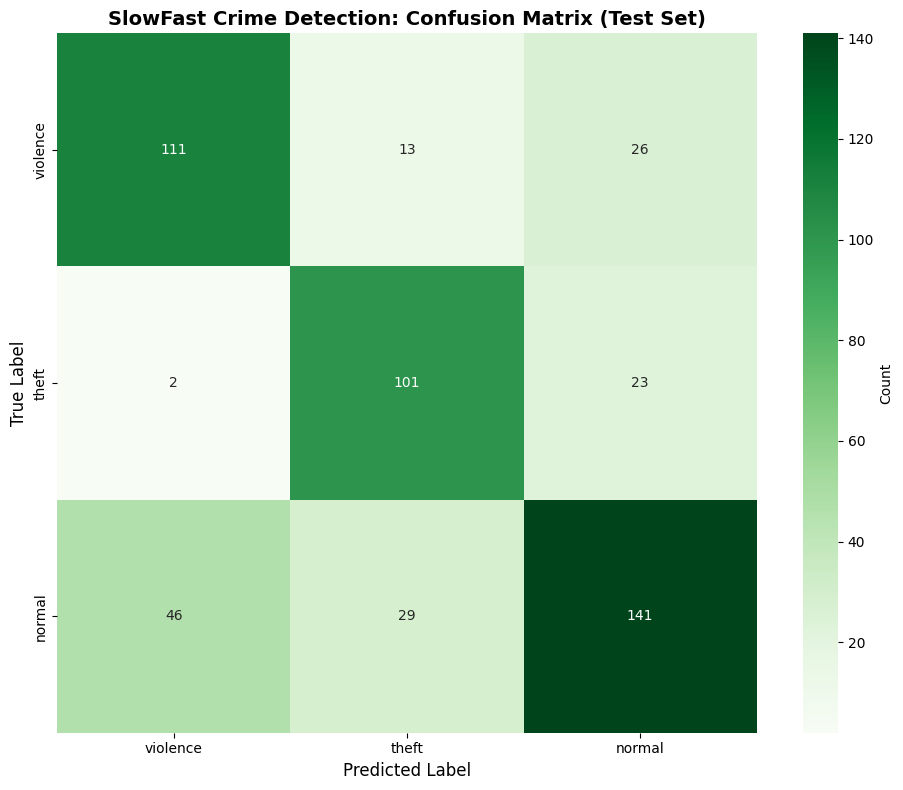


✓ Confusion matrix saved


In [35]:
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=MAIN_CLASSES, yticklabels=MAIN_CLASSES,
            cbar_kws={'label': 'Count'}, square=True)
plt.title('SlowFast Crime Detection: Confusion Matrix (Test Set)',
          fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.savefig('/kaggle/working/slowfast_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Confusion matrix saved")

## 15. Training History Visualization

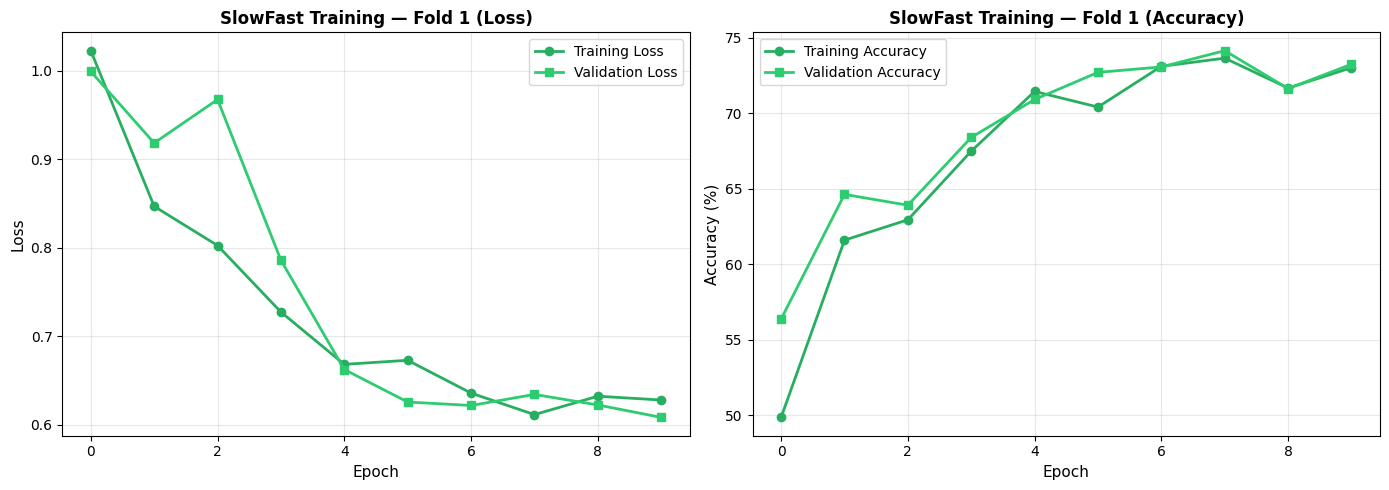


✓ Training history saved


In [36]:
best_result = fold_results[0]  # single fold
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(best_result['train_losses'], 'o-', label='Training Loss',
             linewidth=2, color='#27ae60')
axes[0].plot(best_result['val_losses'],   's-', label='Validation Loss',
             linewidth=2, color='#2ecc71')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Loss', fontsize=11)
axes[0].set_title(f'SlowFast Training — Fold {best_fold} (Loss)',
                  fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10); axes[0].grid(True, alpha=0.3)

axes[1].plot(best_result['train_accs'], 'o-', label='Training Accuracy',
             linewidth=2, color='#27ae60')
axes[1].plot(best_result['val_accs'],   's-', label='Validation Accuracy',
             linewidth=2, color='#2ecc71')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy (%)', fontsize=11)
axes[1].set_title(f'SlowFast Training — Fold {best_fold} (Accuracy)',
                  fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/slowfast_training_history.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Training history saved")

## 16. Benchmark Summary

In [37]:
f1   = f1_score(test_labels, test_preds, average='macro')
prec = precision_score(test_labels, test_preds, average='macro')
rec  = recall_score(test_labels, test_preds, average='macro')

print("\n" + "="*60)
print("SLOWFAST BENCHMARK RESULTS")
print("="*60)
print(f"  Model           : SlowFast-R50 / SlowFast Custom")
print(f"  Slow frames     : {SLOW_FRAMES}")
print(f"  Fast frames     : {FAST_FRAMES}   (alpha={ALPHA})")
print(f"  Image size      : {IMG_SIZE}x{IMG_SIZE}")
print(f"  K-Folds         : {K_FOLDS}")
print(f"  Epochs          : {EPOCHS}")
print(f"  Best Val Fold   : {best_fold} ({best_fold_acc:.2f}%)")
print(f"  Test Accuracy   : {test_acc:.2f}%")
print(f"  Macro F1-Score  : {f1:.4f}")
print(f"  Macro Precision : {prec:.4f}")
print(f"  Macro Recall    : {rec:.4f}")
print("="*60)


SLOWFAST BENCHMARK RESULTS
  Model           : SlowFast-R50 / SlowFast Custom
  Slow frames     : 8
  Fast frames     : 32   (alpha=4)
  Image size      : 224x224


NameError: name 'K_FOLDS' is not defined